In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("credit_card_fraud_10k.csv")

# EDA

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 781.4 KB


In [4]:
df.describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


In [5]:
df[df['is_fraud'] == 1].describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000,151.000000,151.0
mean,4763.741722,216.182980,3.841060,0.543046,0.476821,37.867550,3.205298,43.397351,1.0
std,2801.948502,248.120467,5.803554,0.499801,0.501125,16.179277,1.953861,14.490953,0.0
min,58.000000,0.110000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,1.0
25%,2283.500000,41.530000,1.000000,0.000000,0.000000,28.500000,2.000000,31.500000,1.0
50%,4518.000000,118.940000,2.000000,1.000000,0.000000,32.000000,3.000000,44.000000,1.0
75%,7053.500000,341.695000,3.000000,1.000000,1.000000,38.000000,5.000000,55.500000,1.0
max,9974.000000,1185.070000,23.000000,1.000000,1.000000,99.000000,7.000000,69.000000,1.0


Some things noticed with the fraudulent transactions:
- Somewhat higher amounts
- More frequent during certain hours (middle of night)
- Lower device trust scores
- Much more likely to be foreign transactions

In [6]:
df.duplicated().sum()

np.int64(0)

### Classes

In [7]:
df["is_fraud"].value_counts()

is_fraud
0    9849
1     151
Name: count, dtype: int64

### Numeric histograms

In [8]:
numeric_cols = ['amount', 'transaction_hour', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']
categorical_cols = ['foreign_transaction', 'location_mismatch', 'merchant_category']

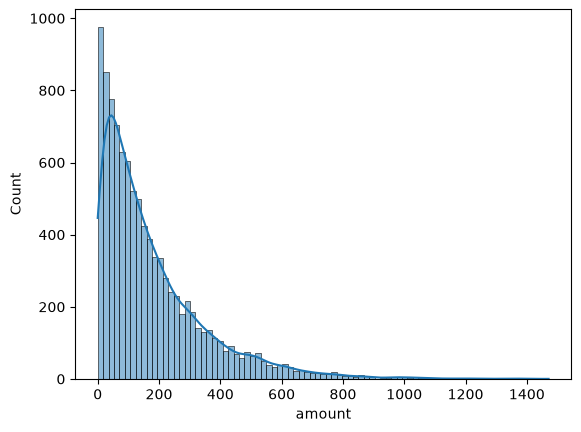

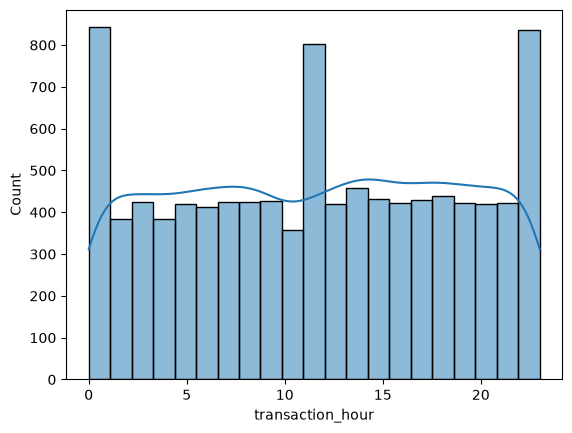

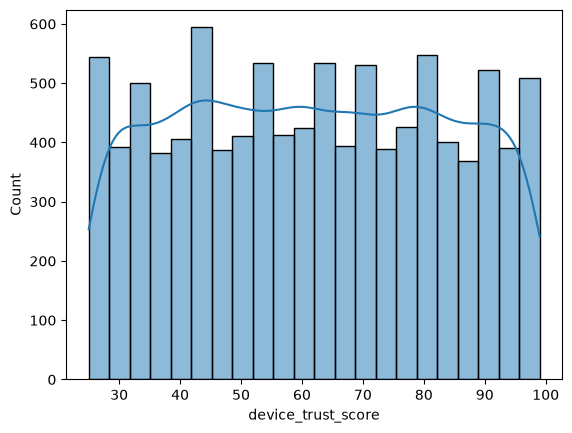

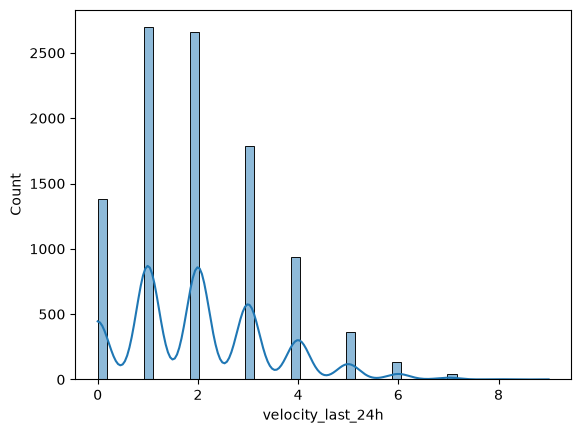

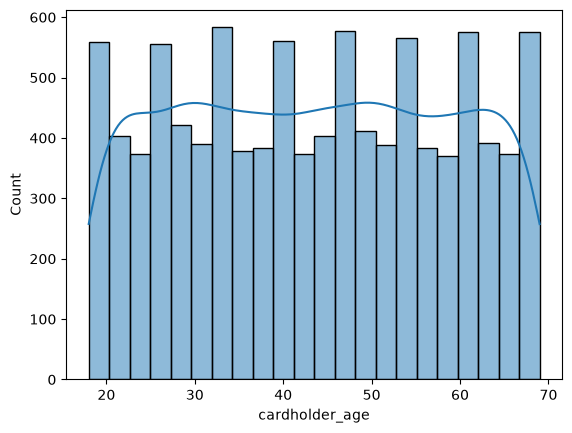

In [9]:
for col in numeric_cols:
        plt.figure()
        sns.histplot(df[col], kde=True)
        plt.show()


### Check outliers with z-score

In [10]:
for col in numeric_cols:
    z_scores = (df[col] - df[col].mean()) / df[col].std()
    outliers = df[z_scores.abs() > 3]
    print(f"{col}: {len(outliers)} outliers")

amount: 180 outliers
transaction_hour: 0 outliers
device_trust_score: 0 outliers
velocity_last_24h: 51 outliers
cardholder_age: 0 outliers


In [11]:
col = 'amount'
outliers = (df[col] - df[col].mean()) / df[col].std() > 3
df[outliers].describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,4648.861111,871.457389,10.983333,0.116667,0.100000,64.338889,1.961111,44.322222,0.050000
std,2865.772706,161.558399,7.361742,0.321918,0.300837,21.174762,1.300468,15.163414,0.218553
min,70.000000,703.400000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2009.750000,751.620000,4.000000,0.000000,0.000000,48.000000,1.000000,30.750000,0.000000
50%,4516.000000,817.005000,10.000000,0.000000,0.000000,65.000000,2.000000,45.000000,0.000000
75%,6841.250000,969.707500,18.000000,0.000000,0.000000,83.000000,3.000000,57.000000,0.000000
max,9928.000000,1471.040000,23.000000,1.000000,1.000000,99.000000,5.000000,69.000000,1.000000


In [12]:
col = 'velocity_last_24h'
outliers = (df[col] - df[col].mean()) / df[col].std() > 3
df[outliers].describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,4704.117647,149.440588,10.627451,0.019608,0.078431,59.313725,7.235294,39.705882,0.078431
std,2863.934822,153.474801,7.113257,0.140028,0.271524,23.250368,0.550935,14.281868,0.271524
min,34.000000,2.280000,0.000000,0.000000,0.000000,26.000000,7.000000,20.000000,0.000000
25%,2196.000000,47.690000,4.000000,0.000000,0.000000,38.000000,7.000000,28.000000,0.000000
50%,4420.000000,98.970000,11.000000,0.000000,0.000000,55.000000,7.000000,36.000000,0.000000
75%,7837.500000,211.970000,16.000000,0.000000,0.000000,80.500000,7.000000,48.000000,0.000000
max,9872.000000,629.530000,22.000000,1.000000,1.000000,98.000000,9.000000,68.000000,1.000000


# Modeling and evaluation

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import ConfusionMatrixDisplay


X = df[numeric_cols + categorical_cols]
y = df['is_fraud']


def build_pipeline(clf, numeric_cols, categorical_cols):
    """Shared impute+scale(+encode) preprocessing wrapped around any clf."""
    numeric_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='mean')),
        ('scale', StandardScaler()),
    ])

    preprocessor = ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_cols),
        # drop='if_binary': a 2-category column (whether 0/1 ints or two
        # strings) only needs 1 column to represent fully -- one-hot
        # encoding it into 2 columns creates two perfectly redundant,
        # mirror-image columns, which splits/hides a tree model's real
        # feature importance across both instead of showing it on one.
        # Columns with 3+ categories still get full one-hot encoding.
        ('categorical', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), categorical_cols),
    ])

    return Pipeline([
        ('preprocess', preprocessor),
        ('clf', clf),
    ])


def evaluate_classifier(clf, X, y, numeric_cols, categorical_cols, n_splits=5, random_state=42):
    """
    Runs stratified k-fold CV for a given (unfitted) classifier and
    prints/returns average accuracy, macro precision, and macro recall.

    Pass any unfitted sklearn-compatible classifier (LogisticRegression,
    RandomForestClassifier, xgboost.XGBClassifier, ...) -- the preprocessing
    and CV setup stays identical, only `clf` changes. `y` is label-encoded
    to integers here because some classifiers (XGBoost) require integer
    class labels 0..n_classes-1 and won't accept raw strings, unlike
    sklearn's own classifiers which accept either.
    """
    pipeline = build_pipeline(clf, numeric_cols, categorical_cols)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    y_enc = LabelEncoder().fit_transform(y)

    # Macro averaging: treats both classes equally regardless of size, which
    # matters a lot here since fraud is only ~1.5% of the data -- plain
    # accuracy alone would look great even from always predicting "not fraud".
    scores = cross_validate(
        pipeline, X, y_enc, cv=cv,
        scoring=['accuracy', 'precision_macro', 'recall_macro'],
    )

    print(f"Accuracy:          {scores['test_accuracy'].mean():.3f} (+/- {scores['test_accuracy'].std():.3f})")
    print(f"Precision (macro): {scores['test_precision_macro'].mean():.3f} (+/- {scores['test_precision_macro'].std():.3f})")
    print(f"Recall (macro):    {scores['test_recall_macro'].mean():.3f} (+/- {scores['test_recall_macro'].std():.3f})")
    return scores


def plot_confusion_matrix_cv(clf, X, y, numeric_cols, categorical_cols, n_splits=5, random_state=42):
    """
    Confusion matrix built from out-of-fold predictions under the same
    stratified CV split as evaluate_classifier, so it reflects the same
    cross-validated performance rather than a single train/test split.
    Rows = true is_fraud, columns = predicted is_fraud; cell (i, j) = number
    of samples whose true label is i but were predicted as j (the diagonal
    is correct predictions). `y` is label-encoded for the same reason as in
    evaluate_classifier, then predictions are decoded back to the original
    0/1 labels so the plot stays readable.
    """
    pipeline = build_pipeline(clf, numeric_cols, categorical_cols)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    le = LabelEncoder()
    y_enc = le.fit_transform(y)
    y_pred_enc = cross_val_predict(pipeline, X, y_enc, cv=cv)
    y_pred = le.inverse_transform(y_pred_enc)
    ConfusionMatrixDisplay.from_predictions(y, y_pred, xticks_rotation=45)
    return y_pred


# Logistic Regression

Accuracy:          0.991 (+/- 0.001)
Precision (macro): 0.905 (+/- 0.018)
Recall (macro):    0.741 (+/- 0.029)


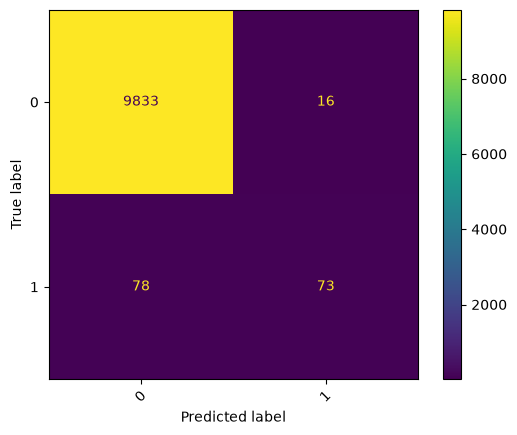

In [14]:
from sklearn.linear_model import LogisticRegression

scores = evaluate_classifier(
    LogisticRegression(max_iter=1000), X, y, numeric_cols, categorical_cols,
)
y_pred = plot_confusion_matrix_cv(
    LogisticRegression(max_iter=1000), X, y, numeric_cols, categorical_cols,
)

# Random Forest

Accuracy:          0.996 (+/- 0.001)
Precision (macro): 0.998 (+/- 0.000)
Recall (macro):    0.878 (+/- 0.020)


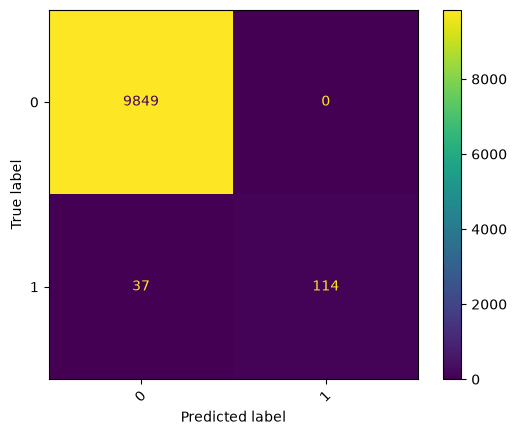

In [15]:
from sklearn.ensemble import RandomForestClassifier

scores = evaluate_classifier(RandomForestClassifier(random_state=42, class_weight='balanced'), X, y, numeric_cols, categorical_cols)
y_pred = plot_confusion_matrix_cv(RandomForestClassifier(random_state=42, class_weight='balanced'), X, y, numeric_cols, categorical_cols)

# XGBoost

Accuracy:          1.000 (+/- 0.000)
Precision (macro): 0.993 (+/- 0.008)
Recall (macro):    0.990 (+/- 0.013)


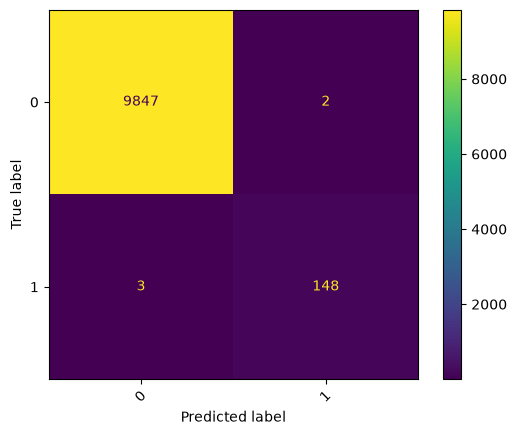

In [16]:
from xgboost import XGBClassifier

# https://xgboost.readthedocs.io/en/stable/parameter.html
scores = evaluate_classifier(XGBClassifier(scale_pos_weight=10), X, y, numeric_cols, categorical_cols)
y_pred = plot_confusion_matrix_cv(XGBClassifier(scale_pos_weight=10), X, y, numeric_cols, categorical_cols)

# Feature importance

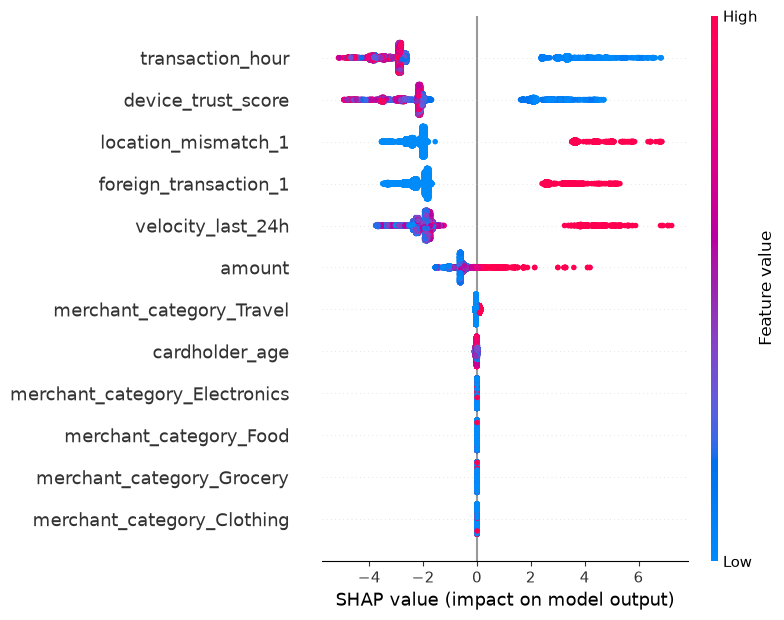

In [17]:
import shap


def plot_shap_summary(clf, X, y, numeric_cols, categorical_cols):
    """
    SHAP explains the predictions of one fitted model -- it doesn't map
    cleanly onto k-fold CV, which trains 5 *different* models (one per fold)
    rather than one. Standard practice decouples the two concerns: CV
    answers "how well does this approach generalize," which is a separate
    question from "what did the model learn." So here we fit one model on
    the FULL dataset purely for interpretation -- this is also the model
    you'd actually deploy, after CV already validated the approach
    separately. These SHAP values describe this one model's behavior, not
    an out-of-sample estimate of it (a more rigorous but more expensive
    alternative is out-of-fold SHAP, mirroring cross_val_predict above --
    worth doing if you need every sample explained by a model that never
    saw it in training).
    """
    pipeline = build_pipeline(clf, numeric_cols, categorical_cols)
    pipeline.fit(X, y)

    fitted_clf = pipeline.named_steps['clf']
    preprocessor = pipeline.named_steps['preprocess']
    X_transformed = preprocessor.transform(X)
    # Pull the real post-encoding names from the fitted ColumnTransformer --
    # numeric_cols + categorical_cols is wrong once any categorical column
    # is actually one-hot encoded, since OneHotEncoder expands each
    # categorical column into one column per category (e.g. 2 categorical
    # columns here become 4 after encoding), so the name list no longer
    # matches X_transformed's actual column count.
    feature_names = [name.split('__', 1)[-1] for name in preprocessor.get_feature_names_out()]

    # Tree models (RandomForest, XGBoost) get an exact, fast explainer with
    # no background data needed; other models (e.g. LogisticRegression) need
    # a background dataset to build their explainer against, so fall back to
    # passing one if the no-background form isn't supported for this clf.
    try:
        explainer = shap.Explainer(fitted_clf, feature_names=feature_names)
    except Exception:
        explainer = shap.Explainer(fitted_clf, X_transformed, feature_names=feature_names)
    shap_values = explainer(X_transformed)

    if shap_values.values.ndim == 3:
        # Multiclass: shap_values.values is (n_samples, n_features, n_classes).
        # The classic summary_plot multiclass form wants a list of per-class
        # (n_samples, n_features) arrays, and shows one bar per class per feature.
        values_list = [shap_values.values[:, :, i] for i in range(shap_values.values.shape[2])]
        shap.summary_plot(
            values_list, X_transformed,
            feature_names=feature_names, class_names=list(fitted_clf.classes_),
        )
    else:
        # Binary: already (n_samples, n_features) -- one set of SHAP values
        # is enough, since the negative class's contribution is just the
        # negation of the positive class's.
        shap.summary_plot(shap_values.values, X_transformed, feature_names=feature_names)

    return shap_values


shap_values = plot_shap_summary(
    XGBClassifier(scale_pos_weight=10), X, y, numeric_cols, categorical_cols,
)